# Activity7.01: Finding patterns in flight passengers' data

LU MENGJIE — MC643920  
Suggested Exercise 07 · Practice 01

Data: `flight_details.csv`. The tutorial step mentioning Activity7.02 is a numbering typo; this Practice 01 item is Activity7.01.

## Activity7.01 — 01. Read the monthly flight data

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

DATA_DIR = Path('../../Datasets')
pd.set_option('display.max_columns', 8)
pd.set_option('display.width', 110)
print('LU MENGJIE | MC643920 | Python 3 / Seaborn', sns.__version__)
sns.set_theme()
flights = pd.read_csv(DATA_DIR / 'flight_details.csv')
print('Input shape:', flights.shape)
print('Years:', flights['Years'].min(), 'to', flights['Years'].max())
display(flights.head())

LU MENGJIE | MC643920 | Python 3 / Seaborn 0.13.2
Input shape: (144, 3)
Years: 1949 to 1960


,Years,Months,Passengers
0,1949,January,112
1,1949,February,118
2,1949,March,132
3,1949,April,129
4,1949,May,121


## Activity7.01 — 02. Pivot by month and year and choose a sequential palette

In [2]:
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
data = flights.pivot(index='Months', columns='Years', values='Passengers')
data = data.reindex(month_order)
flight_colormap = sns.color_palette('crest', as_cmap=True)
print('Heatmap shape:', data.shape)
print('Passenger range (thousands):', data.min().min(), 'to', data.max().max())
display(data.iloc[:4, :5])

Heatmap shape: (12, 12)
Passenger range (thousands): 104 to 622


Years,1949,1950,1951,1952,1953
Months,,,,,
January,112,115,145,171,196
February,118,126,150,180,196
March,132,141,178,193,236
April,129,135,163,181,235


## Activity7.01 — 03. Draw the passenger heatmap

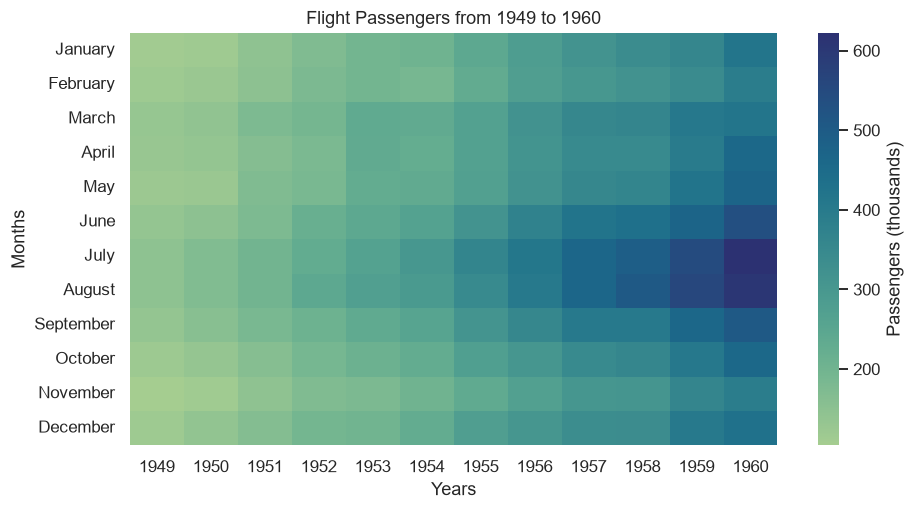

In [3]:
plt.figure(figsize=(8.8, 4.8), dpi=110)
sns.heatmap(data, cmap=flight_colormap,
            cbar_kws={'label': 'Passengers (thousands)'})
plt.title('Flight Passengers from 1949 to 1960')
plt.xlabel('Years')
plt.ylabel('Months')
plt.tight_layout()
plt.show()

Passenger numbers rise over time, with recurring summer peaks around July and August. A sequential palette is appropriate for nonnegative counts; it does not imply a positive/negative reference point.